# 2. Maps

This notebook draws these maps in the paper:

- Search Interest by prefecture: Figure 1a (2004–2010), Figure 2a (2011) and Figure 3a–c (2012–2014, 2015–2019,
  2020–2024);
- the comparison-mode results for the auxiliary terms: Figure 4 ("definition queries" against "update queries")
  and Figure 5 ("how-to queries" against "countermeasure queries").

The reactor markers and labels in Figures 1a and 3 were added by hand afterwards and are not drawn here.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from japanmap import picture

DATA = Path("../data")
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "figure.dpi": 150,
})

prefectures = pd.read_csv(DATA / "prefectures.csv")

def color_map(ax, values, cmap, norm):
    """Color each prefecture by its value; `values` is indexed by prefecture code."""
    colors = values.apply(lambda v: "#" + bytes(cmap(norm(v), bytes=True)[:3]).hex())
    ax.imshow(picture(colors))
    ax.axis("off")

def interest(period):
    return prefectures.set_index("code")[f"search_interest_{period}"]

## Figure 1a: Search Interest, 2004–2010

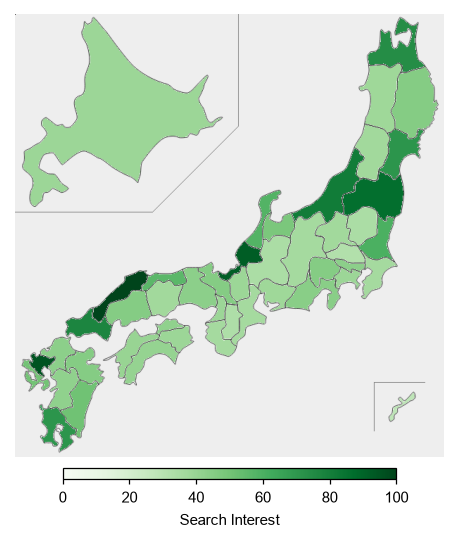

In [2]:
fig, ax = plt.subplots(figsize=(3.05, 3.5), layout="constrained")
norm = plt.Normalize(0, interest("2004-2010").max())
color_map(ax, interest("2004-2010"), plt.get_cmap("Greens"), norm)
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="Greens"), ax=ax, location="bottom", shrink=0.75, aspect=30, pad=0.02)
cb.set_label("Search Interest")
plt.show()

## Figure 2a: Search Interest, 2011

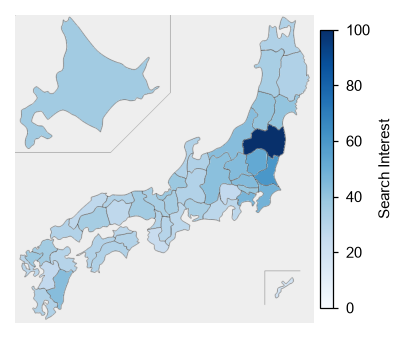

In [3]:
fig, ax = plt.subplots(figsize=(2.6, 2.4), layout="constrained")
norm = plt.Normalize(0, interest("2011").max())
color_map(ax, interest("2011"), plt.get_cmap("Blues"), norm)
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="Blues"), ax=ax, shrink=0.8, aspect=20, pad=0.02)
cb.set_label("Search Interest")
plt.show()

## Figure 3a–c: Search Interest, 2012–2024

The three maps share one color scale.

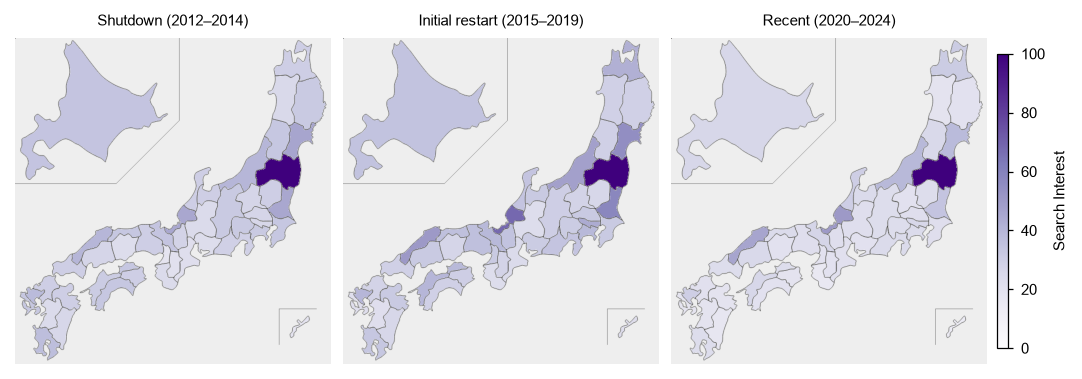

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(7.1, 2.7), layout="constrained")
norm = plt.Normalize(0, 100)
for ax, (period, title) in zip(axes, [("2012-2014", "Shutdown (2012–2014)"), ("2015-2019", "Initial restart (2015–2019)"),
                                      ("2020-2024", "Recent (2020–2024)")]):
    color_map(ax, interest(period), plt.get_cmap("Purples"), norm)
    ax.set_title(title)
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="Purples"), ax=axes, shrink=0.75, aspect=25, pad=0.01)
cb.set_label("Search Interest")
plt.show()

## Figures 4 and 5: which auxiliary term led in each prefecture

In each comparison-mode file, the shares of the two terms add up to 100% in every prefecture.
Each prefecture is colored by the term with the larger share, and the shade shows how large that share is.

In [5]:
SHARE = plt.Normalize(50, 100)

def ramp(name, side):
    """Half of a ColorBrewer diverging map, light to dark, starting from a pale tint instead of white."""
    half = plt.get_cmap(name)(np.linspace(0.5, 0.0 if side == "low" else 1.0, 256))
    light_to_dark = LinearSegmentedColormap.from_list(f"{name}-{side}", half)
    return LinearSegmentedColormap.from_list(f"{name}-{side}-tint", light_to_dark(np.linspace(0.2, 1.0, 256)))

BROWN, TEAL = ramp("BrBG", "low"), ramp("BrBG", "high")

def leading_term_map(ax, shares, first, second):
    d = shares.merge(prefectures[["prefecture", "code"]], on="prefecture").set_index("code")
    assert len(d) == 47 and (d[first] + d[second]).eq(100).all()
    first_leads = d[first] > d[second]
    colors = pd.Series({code: "#" + bytes((BROWN if lead else TEAL)(SHARE(max(a, b)), bytes=True)[:3]).hex()
                        for code, lead, a, b in zip(d.index, first_leads, d[first], d[second])})
    ax.imshow(picture(colors))
    ax.axis("off")
    return d.loc[first_leads, "prefecture"].tolist(), d.loc[~first_leads, "prefecture"].tolist()

def share_colorbar(fig, cax, cmap, orientation):
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=SHARE, cmap=cmap), cax=cax, orientation=orientation)
    cb.set_ticks([50, 60, 70, 80, 90, 100])
    cb.outline.set_linewidth(0.6)
    return cb

### Figure 4: "definition queries" (とは) against "update queries" (情報), March 2011

Mar 11–13: definition queries lead in 2 prefectures, update queries in 45
Mar 14–17: definition queries lead in 30 prefectures, update queries in 17
Mar 18–24: definition queries lead in 40 prefectures, update queries in 7
Mar 25–31: definition queries lead in 45 prefectures, update queries in 2


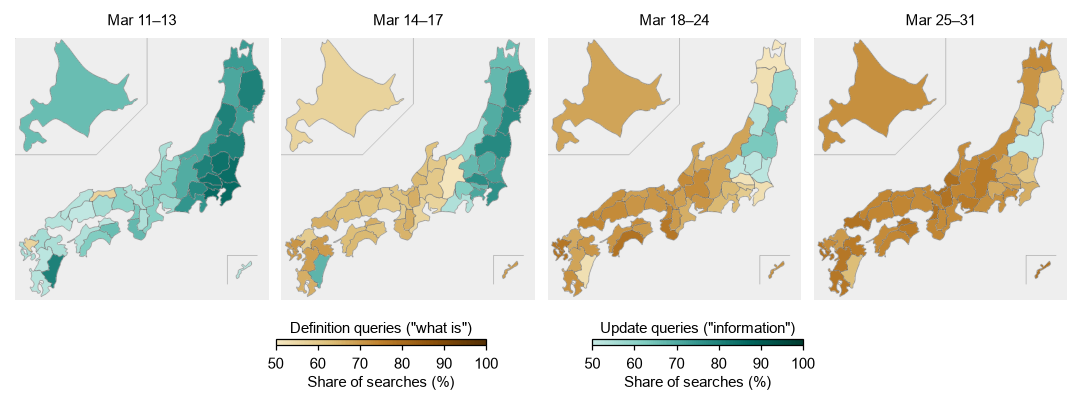

In [6]:
WINDOWS = [("03-11_03-13", "Mar 11–13"), ("03-14_03-17", "Mar 14–17"), ("03-18_03-24", "Mar 18–24"), ("03-25_03-31", "Mar 25–31")]
fig = plt.figure(figsize=(7.1, 2.55), layout="constrained")
top, bottom = fig.subfigures(2, 1, height_ratios=[1.0, 0.27])
for ax, (window, title) in zip(top.subplots(1, 4), WINDOWS):
    shares = pd.read_csv(DATA / "queries" / f"shares_definition_update_{window}.csv")
    definition_leads, update_leads = leading_term_map(ax, shares, "definition_pct", "update_pct")
    ax.set_title(title)
    print(f"{title}: definition queries lead in {len(definition_leads)} prefectures, update queries in {len(update_leads)}")
gs = bottom.add_gridspec(1, 5, width_ratios=[1.2, 1, 0.35, 1, 1.2])
for col, cmap, label in [(1, BROWN, 'Definition queries ("what is")'), (3, TEAL, 'Update queries ("information")')]:
    cax = bottom.add_subplot(gs[0, col])
    share_colorbar(bottom, cax, cmap, "horizontal")
    cax.set_title(label, pad=3)
    cax.set_xlabel("Share of searches (%)", labelpad=2)
plt.show()

### Figure 5: "how-to queries" (方法) against "countermeasure queries" (対策), 11–17 March 2011

countermeasure queries lead in: ['Fukushima']


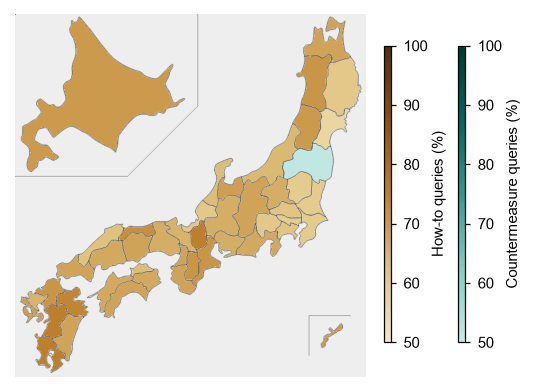

In [7]:
fig = plt.figure(figsize=(3.45, 2.55), layout="constrained")
left, right = fig.subfigures(1, 2, width_ratios=[2.45, 1.0])
shares = pd.read_csv(DATA / "queries" / "shares_howto_countermeasure_03-11_03-17.csv")
howto_leads, countermeasure_leads = leading_term_map(left.subplots(), shares, "howto_pct", "countermeasure_pct")
print("countermeasure queries lead in:", countermeasure_leads)
gs = right.add_gridspec(3, 2, height_ratios=[0.1, 1, 0.1])
for col, cmap, label in [(0, BROWN, "How-to queries (%)"), (1, TEAL, "Countermeasure queries (%)")]:
    share_colorbar(right, right.add_subplot(gs[1, col]), cmap, "vertical").set_label(label, labelpad=2)
plt.show()